# 1.4: Drawing shapes

We start by importing our prior solutions into Python:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dummy constants, to be replaced with reasonable order of magnitude estimates:
r_m = 1
L_m = 1
R_m = 1
J_m = 1
K_m = 1
m = 1
mu_x = 1
mu_y = 1

A_x = np.array([[-mu_x / (2*J_m / r_m**2 + m),        0,     r_m*K_m / (2*J_m + m*r_m**2)],
                [1,                                   0,                   0],
                [0,                                   0,              -R_m / L_m]])

A_y = np.array([[-mu_y / (2*J_m / r_m**2 + m),        0,     r_m*K_m / (2*J_m + m*r_m**2)],
                [1,                                   0,                   0],
                [0,                                   0,              -R_m / L_m]])


B = np.array([[0], [0], [1/L_m]])

To draw an ellipsoid, we define a trajectory with a semi-x-axis and a semi-y-axis:

In [2]:
semi_xaxis = 2.0
semi_yaxis = 1.0

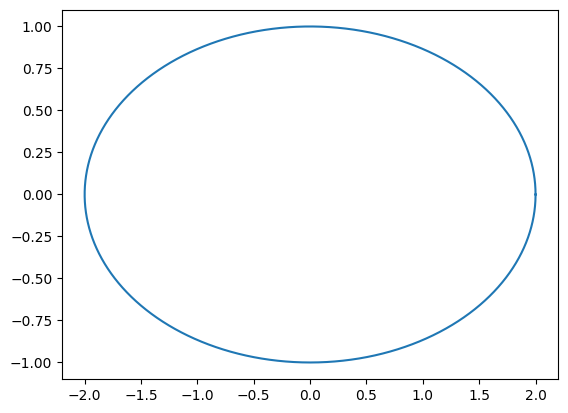

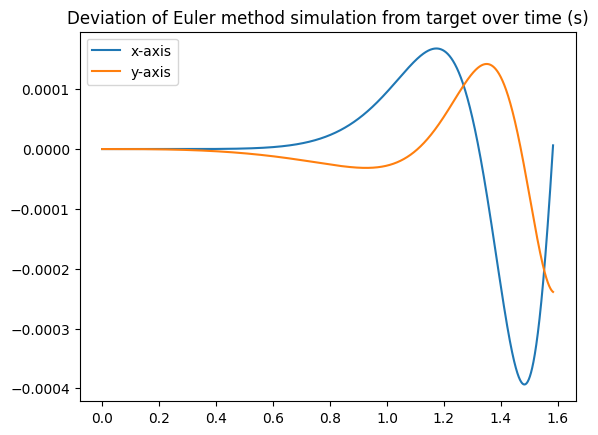

In [3]:
dt = 0.00001
t_end = (2*np.pi)**0.25
t = 0.0

# state initial conditions
x = semi_xaxis
xlist = []
x_d = 0.0
i_x = 0.0
x_x = np.array([[x_d], [x], [i_x]])

y = 0.0
ylist = []
y_d = 0.0
i_y = 0.0
x_y = np.array([[y_d], [y], [i_y]])


# coordinates as numerically calculated, given targets will be x_u and y_u
x_sim = semi_xaxis
y_sim = 0.0
x_simlist = []
y_simlist = []

for t in np.arange(0, t_end, dt):
    x_simlist.append(x_sim)
    y_simlist.append(y_sim)
    
    x_u = semi_xaxis * np.cos(t**4)
    xlist.append(x_u)
    x_u_d = -4*t**3 * semi_xaxis * np.sin(t**4)
    x_u_dd = -12*t**2 * semi_xaxis * np.sin(t**4) - 16*t**6 * semi_xaxis * np.cos(t**4)
    x_u_ddd = -24*t * semi_xaxis * np.sin(t**4) - 144*t**5 * semi_xaxis * np.cos(t**4) + 64*t**9 * semi_xaxis * np.sin(t**4)

    y_u = semi_yaxis * np.sin(t**4)
    ylist.append(y_u)
    y_u_d = 4*t**3 * semi_yaxis * np.cos(t**4)
    y_u_dd = 12*t**2 * semi_yaxis * np.cos(t**4) - 16*t**6 * semi_yaxis * np.sin(t**4)
    y_u_ddd = 24*t * semi_yaxis * np.cos(t**4) - 144*t**5 * semi_yaxis * np.sin(t**4) - 64*t**9 * semi_yaxis * np.cos(t**4)

    u_x = (L_m*(2*J_m + m*r_m**2)*x_u_ddd + (L_m*mu_x*r_m**2 + R_m*(2*J_m + m*r_m**2))*x_u_dd + R_m*mu_x*r_m**2*x_u_d) / (r_m*K_m)
    u_y = (L_m*(2*J_m + m*r_m**2)*y_u_ddd + (L_m*mu_y*r_m**2 + R_m*(2*J_m + m*r_m**2))*y_u_dd + R_m*mu_y*r_m**2*y_u_d) / (r_m*K_m)

    x_x_d = A_x@x_x + B*u_x
    x_y_d = A_y@x_y + B*u_y

    # Apply Euler method
    x_x += x_x_d * dt
    x_y += x_y_d * dt
    x_sim = x_x[1][0]
    y_sim = x_y[1][0]

plt.plot(x_simlist, y_simlist)
plt.show()

plt.title("Deviation of Euler method simulation from target over time (s)")
plt.plot(np.arange(0, t_end, dt), np.array(x_simlist) - np.array(xlist), label='x-axis')
plt.plot(np.arange(0, t_end, dt), np.array(y_simlist) - np.array(ylist), label='y-axis')
plt.legend()
plt.show()

Of course, this particular method accelerates very quickly to unrealistic speeds, but it demonstrates that our tracking works with a nice algebraic function.